In [1]:
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

n = pypsa.Network(
    r"C:\Users\jonat\pypsa-eur-september\pypsa-eur\results\sector_NE_june_july_2025\networks\base_s_10___2025.nc"
)

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.3)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


In [2]:
%config InlineBackend.figure_format = "retina"   # 2x pixel density in the notebook
plt.rcParams["figure.dpi"] = 150                 # inline display resolution (default ~100)
plt.rcParams["savefig.dpi"] = 300                # resolution for fig.savefig(...)

# Save every figure shown in this notebook as SVG (vector - stays sharp in PowerPoint).
import os, re

FIG_DIR = "figures_svg_dispatch"
os.makedirs(FIG_DIR, exist_ok=True)
_orig_show = getattr(plt, "_orig_show", plt.show)  # avoid double-wrapping on re-run
plt._orig_show = _orig_show
_fig_counter = [0]


def _show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = (fig._suptitle.get_text() if fig._suptitle else
                 next((ax.get_title() for ax in fig.axes if ax.get_title()), f"fig_{num}"))
        _fig_counter[0] += 1
        name = re.sub(r"[^\w\- ]", "_", title).strip()[:80]
        fig.savefig(f"{FIG_DIR}/{_fig_counter[0]:02d}_{name}.svg", bbox_inches="tight")
    _orig_show(*args, **kwargs)


plt.show = _show_and_save

In [3]:
# Links that only move energy between buses of the SAME panel at the same node
# (they would show up as +X / -X and cancel) - extend as needed.
# "electricity distribution grid" (AC -> low voltage) is kept on purpose: its two
# ends net to its losses (3 %), so the electricity panel still balances.
EXCLUDE = {"household heat delivery"}
TRANSMISSION = {"DC"}      # link carriers between nodes -> shown as "net import"
OTHER_SHARE = 0.01         # carriers below this share of a panel's |energy| -> "other"


# Map PyPSA-Eur cluster names (country + AC sub-network + cluster + carrier)
# to readable names. Valid for sector_NE runs (10 clusters) - check per run.
NODE_NAMES = {
    "DK0 0AC": "DK2 (East DK)",
    "DK2 0AC": "DK1 (West DK)",
    "DE2 0AC": "DE",
    "NL2 0AC": "NL",
    "NO0 0AC": "NO",
    "SE0 0AC": "SE",
    "FI0 0AC": "FI",
    "GB1 0AC": "GB (mainland)",
    "GB3 0AC": "GB (Orkney/Shetland)",
    "GB4 0AC": "GB (N. Ireland)",
}


def _loc(n):
    loc = n.buses.location.copy() if "location" in n.buses else pd.Series("", index=n.buses.index)
    loc = loc.where(loc.astype(str) != "", n.buses.index.to_series())
    return loc.map(lambda x: NODE_NAMES.get(x, x))


def dispatch(n, bus_carriers, exclude=EXCLUDE):
    """Hourly power [MW] injected into buses with carrier in bus_carriers,
    columns = (node, carrier). Positive = supply to the bus, negative = withdrawal
    (loads, storage charging, heat pump / EV electricity use, exports)."""
    bus_carriers = [bus_carriers] if isinstance(bus_carriers, str) else list(bus_carriers)
    buses = n.buses.index[n.buses.carrier.isin(bus_carriers)]
    loc = _loc(n)
    parts = []

    def add(p, bus, carrier):
        m = bus.isin(buses) & ~carrier.isin(exclude)
        idx = bus.index[m].intersection(p.columns)
        if len(idx):
            cols = pd.MultiIndex.from_arrays([bus[idx].map(loc), carrier[idx]],
                                             names=["node", "carrier"])
            parts.append(pd.DataFrame(p[idx].values, index=p.index, columns=cols))

    # Generators, storage units and stores: p > 0 means power into the bus
    add(n.generators_t.p, n.generators.bus, n.generators.carrier)
    add(n.storage_units_t.p, n.storage_units.bus, n.storage_units.carrier)
    add(n.stores_t.p, n.stores.bus, n.stores.carrier)
    add(-n.loads_t.p, n.loads.bus, n.loads.carrier)

    # Links: p_i > 0 means withdrawal at bus_i -> injection is -p_i (works for every
    # port and for reversed links such as the heat pumps, no efficiencies needed)
    L = n.links
    car = L.carrier.where(~L.carrier.isin(TRANSMISSION), "net import")
    ports = sorted(int(col[3:]) for col in L.columns if col.startswith("bus") and col[3:].isdigit())
    for p in ports:
        if f"p{p}" in n.links_t:
            add(-n.links_t[f"p{p}"], L[f"bus{p}"], car)

    # AC lines: net import into each node
    line_car = pd.Series("net import", index=n.lines.index)
    add(-n.lines_t.p0, n.lines.bus0, line_car)
    add(-n.lines_t.p1, n.lines.bus1, line_car)

    df = pd.concat(parts, axis=1)
    return df.T.groupby(level=["node", "carrier"]).sum().T


def annual_energy(n, df):
    """Annual energy [TWh] per (node, carrier); positive = supply, negative = use."""
    w = n.snapshot_weightings.generators
    e = df.mul(w, axis=0).sum() / 1e6
    return e.rename("TWh").reset_index()


def _colors(n, carriers):
    cmap = plt.get_cmap("tab20")
    col = n.carriers.color if "color" in n.carriers else pd.Series(dtype=str)
    out = []
    for i, c in enumerate(carriers):
        v = col.get(c, "")
        if c == "net import":
            v = "#7f7f7f"
        elif c == "other":
            v = "#d9d9d9"
        out.append(v if isinstance(v, str) and v.strip() else cmap(i % 20))
    return out

In [4]:
PANELS = {
    "Electricity":          (["AC", "low voltage"],     "GW_el"),
    "Urban central heat":   (["urban central heat"],    "GW_th"),
    "Urban decentral heat": (["urban decentral heat"],  "GW_th"),
    "Rural heat":           (["rural heat"],            "GW_th"),
}


def _dispatch_panel(ax, n, df, panel_title, unit, freq="D", period=None):
    """Stacked dispatch for one node; df = hourly MW, columns = carrier.
    Supply stacked above zero, consumption below. Legend shows annual TWh."""
    ax.set_title(panel_title)
    df = df.loc[:, df.abs().sum() > 0]
    if df.empty:
        ax.text(0.5, 0.5, "no dispatch", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([])
        ax.set_yticks([])
        return

    # Lump small carriers into "other" (share of the panel's absolute energy)
    share = df.abs().sum() / df.abs().sum().sum()
    small = share.index[share < OTHER_SHARE]
    if len(small) > 1:
        df = df.drop(columns=small).assign(other=df[small].sum(axis=1))

    w = n.snapshot_weightings.generators
    energy = df.mul(w, axis=0).sum() / 1e6  # TWh, full year
    order = df.abs().sum().sort_values(ascending=False).index
    colors = dict(zip(order, _colors(n, order)))

    if period is not None:
        df = df.loc[period[0]:period[1]]
    if freq:
        df = df.resample(freq).mean()
    df = df[order] / 1e3  # MW -> GW

    pos, neg = df.clip(lower=0), df.clip(upper=0)
    pos = pos.loc[:, pos.abs().sum() > 0]
    neg = neg.loc[:, neg.abs().sum() > 0]
    if not pos.empty:
        ax.stackplot(df.index, pos.T.values, colors=[colors[c] for c in pos], lw=0)
    if not neg.empty:
        ax.stackplot(df.index, neg.T.values, colors=[colors[c] for c in neg], lw=0)
    ax.axhline(0, color="k", lw=0.8)

    handles = [Patch(facecolor=colors[c], label=f"{c} ({energy[c]:+.2f} TWh)") for c in order]
    ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left",
              fontsize=7, frameon=False)
    ax.set_ylabel(f"Dispatch [{unit}]")
    ax.set_xlim(df.index[0], df.index[-1])
    if period is None:
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    else:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)


def plot_node_dispatch(n, panels=PANELS, freq="D", period=None, nodes=None,
                       figsize=(22, 12), save_dir=None):
    """One 2x2 figure per node: electricity + the three heat systems.
    freq   : resampling of the hourly dispatch ("D" daily mean, "W" weekly, None = hourly)
    period : optional (start, end) to zoom in, e.g. ("2013-01-07", "2013-01-14")
    """
    dfs = {name: dispatch(n, bus_carriers) for name, (bus_carriers, _) in panels.items()}
    all_nodes = sorted(set().union(*(df.columns.get_level_values("node") for df in dfs.values())))
    nodes = all_nodes if nodes is None else [x for x in nodes if x in all_nodes]
    res = {"D": "daily mean", "W": "weekly mean", None: "hourly"}.get(freq, f"{freq} mean")

    for node in nodes:
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        for ax, (name, (_, unit)) in zip(axes.flat, panels.items()):
            df = dfs[name]
            sub = df[node] if node in df.columns.get_level_values("node") else pd.DataFrame()
            _dispatch_panel(ax, n, sub, name, unit, freq=freq, period=period)

        fig.suptitle(f"{node} - dispatch ({res})", fontsize=18, fontweight="bold")
        fig.tight_layout()
        if save_dir:
            safe = "".join(c if c.isalnum() or c in "-_ " else "_" for c in node)
            fig.savefig(f"{save_dir}/dispatch_{safe}.png", dpi=200, bbox_inches="tight")
        plt.show()

    return dfs

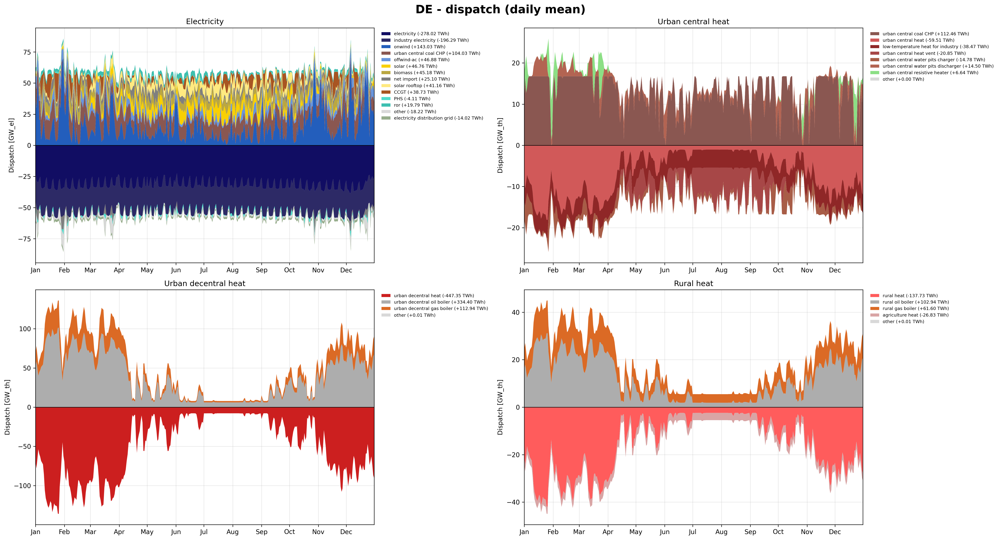

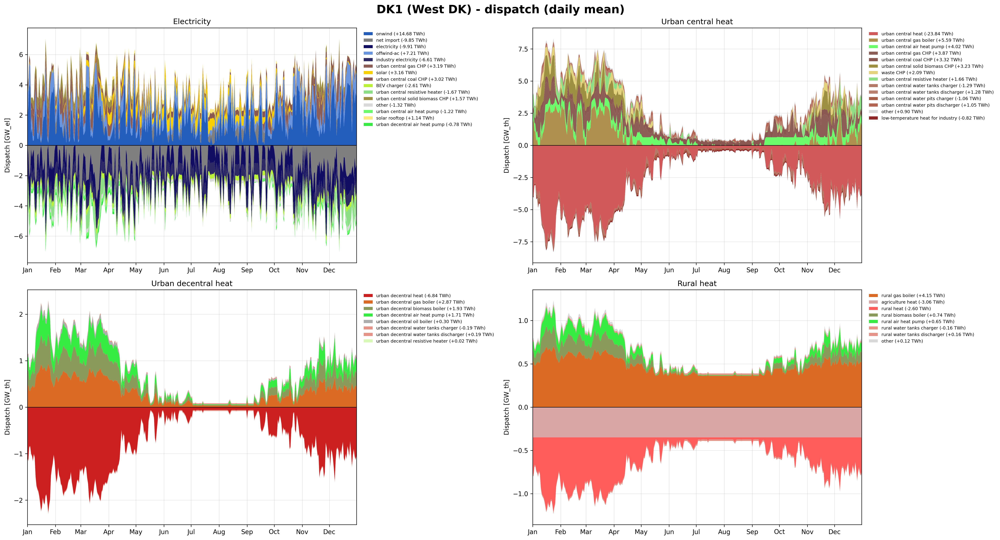

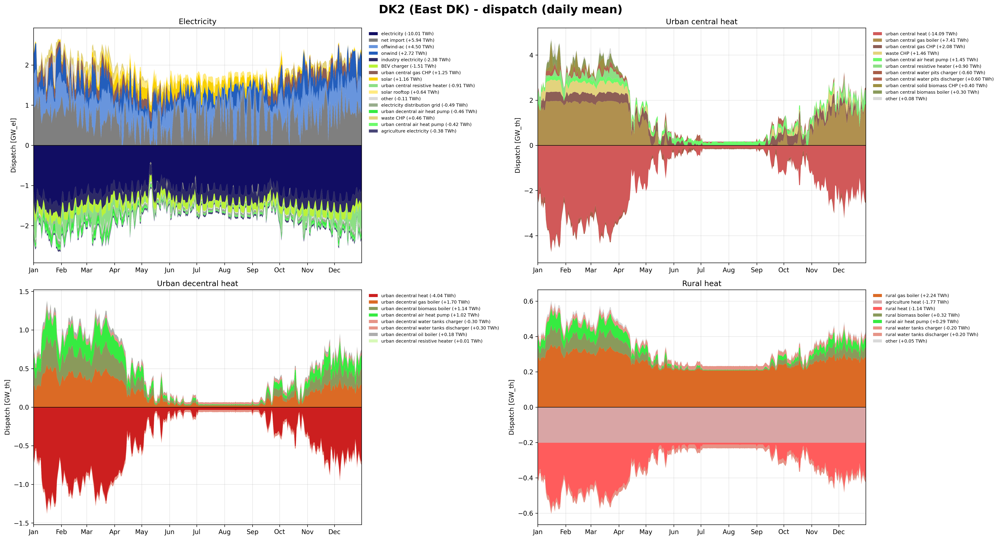

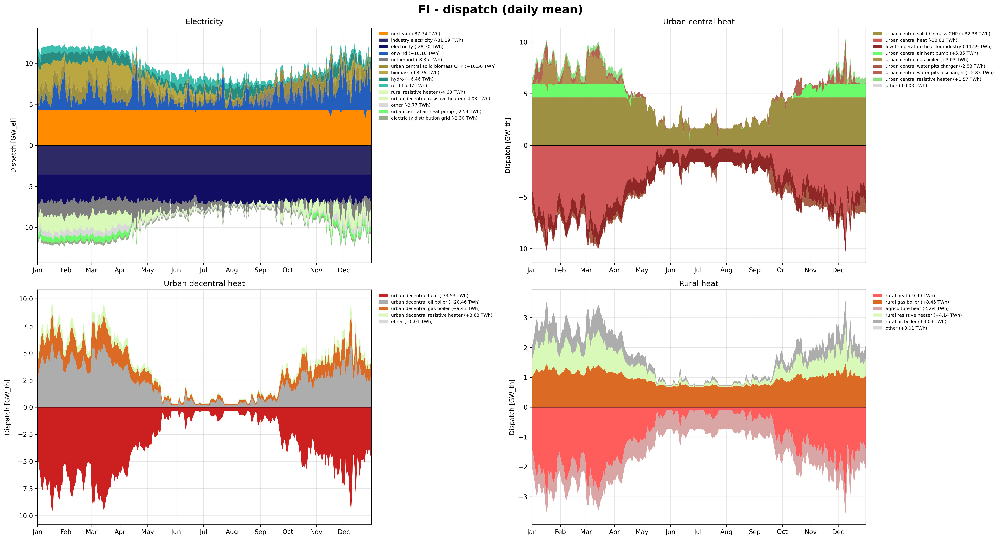

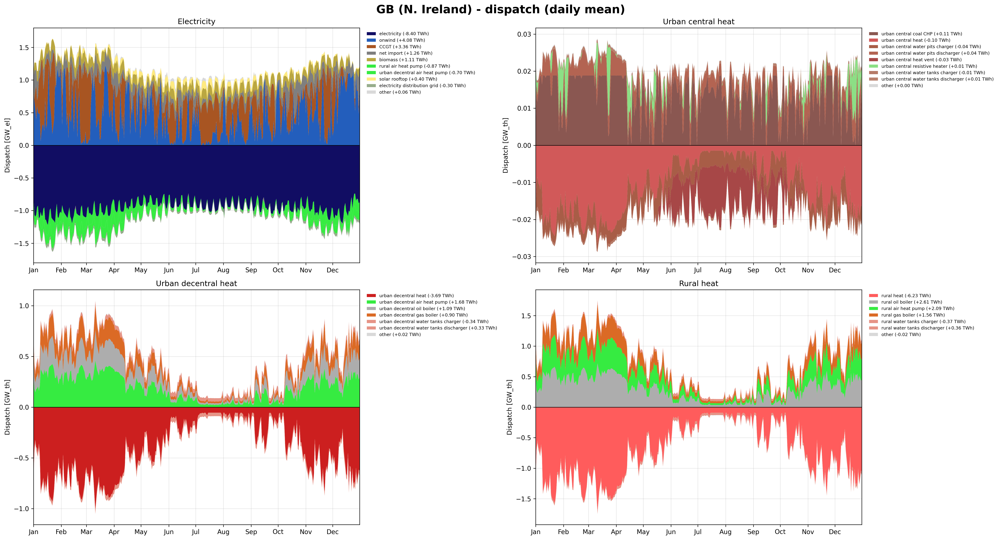

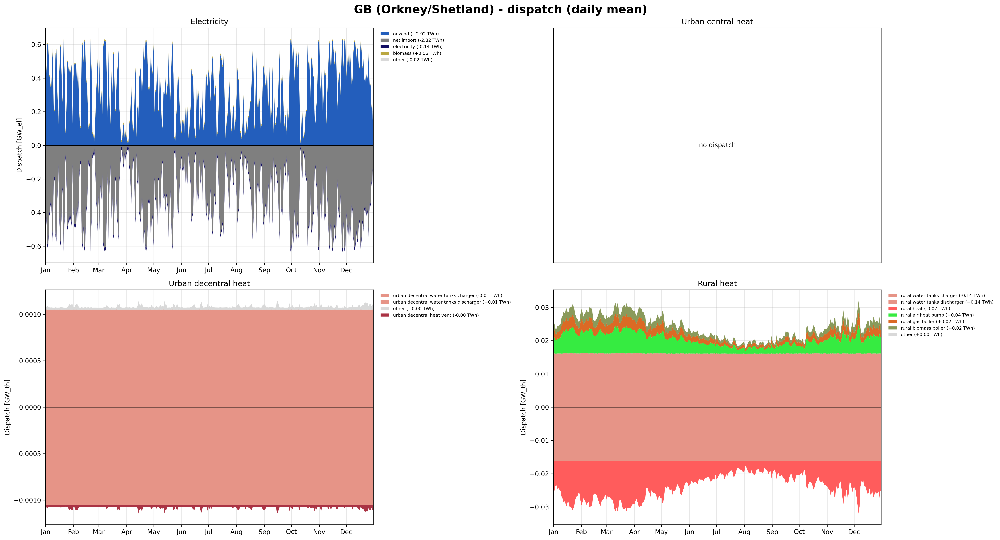

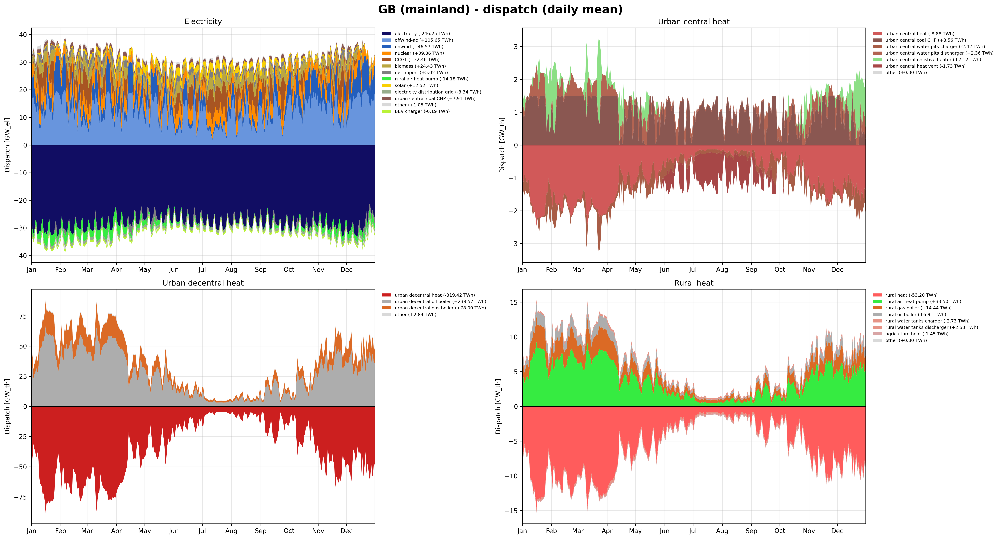

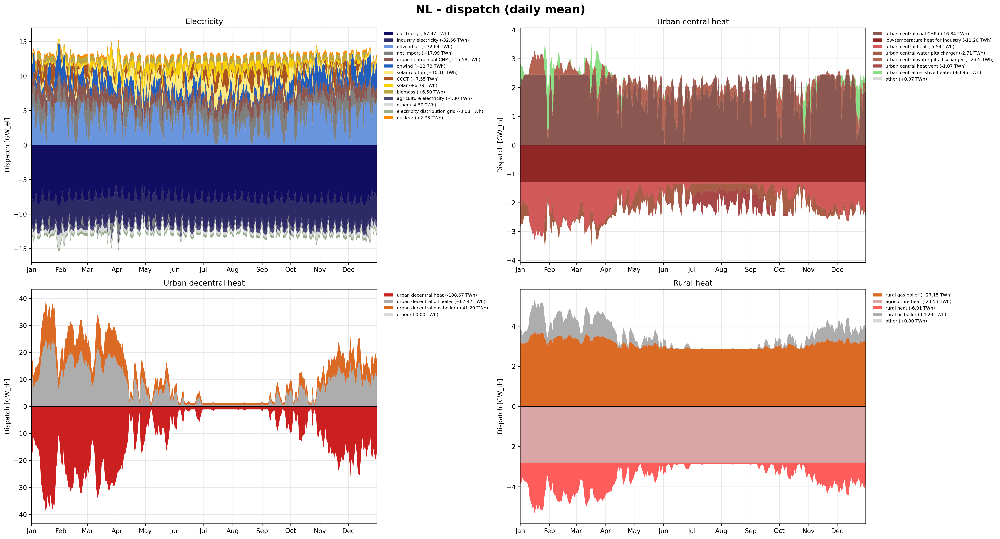

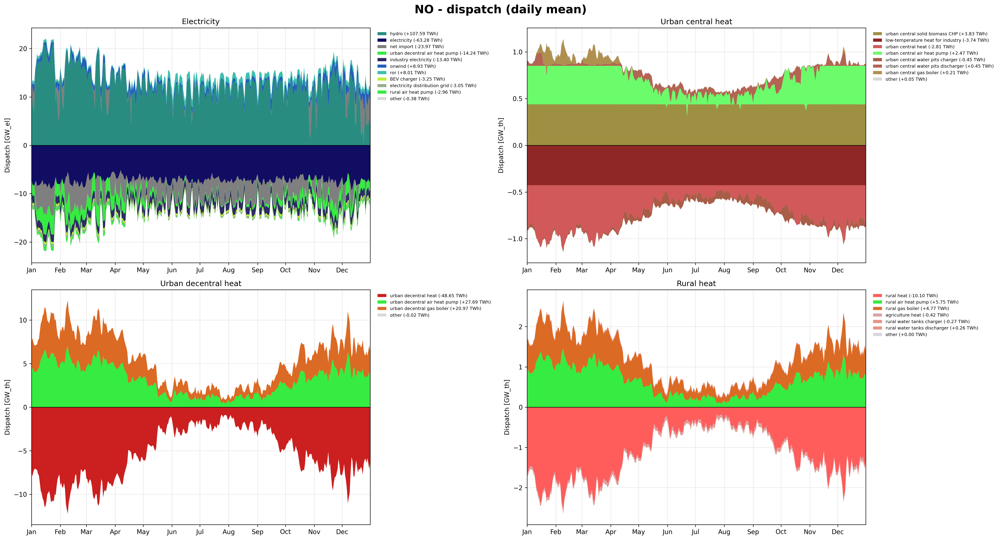

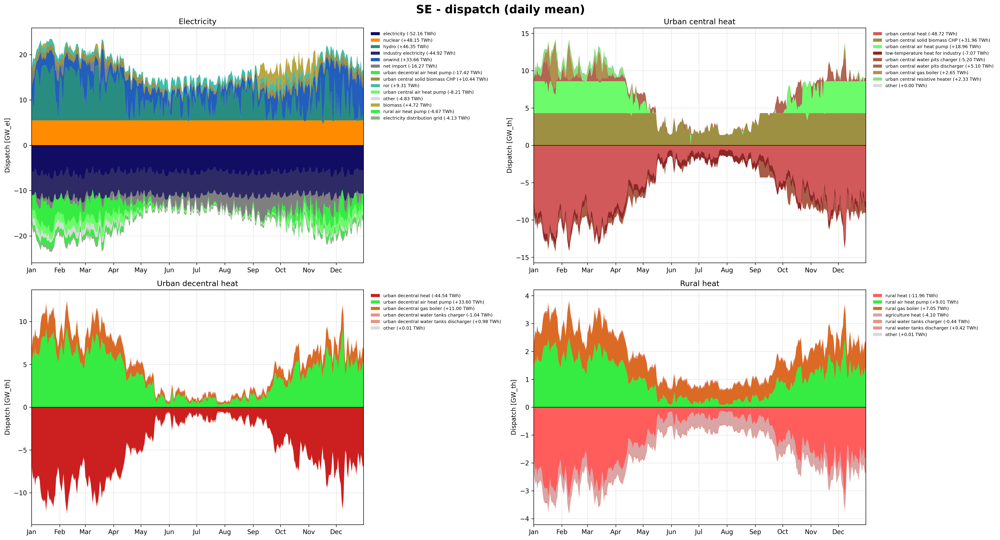

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,
Fischer-Tropsch,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
H2 Electrolysis,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Sabatier,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
low-temperature heat for industry,-38.470,-0.820,-0.240,-11.590,0.000,0.000,-11.200,-3.740,-7.070
methanolisation,0.000,0.000,0.000,0.027,0.000,0.000,0.000,0.047,0.000
urban central air heat pump,0.000,4.023,1.454,5.355,0.000,0.000,0.000,2.469,18.959
urban central biomass boiler,0.000,0.081,0.305,0.000,0.000,0.000,0.000,0.000,0.000
urban central coal CHP,112.460,3.315,0.000,0.000,0.113,8.555,16.840,0.000,0.000
urban central coal CHP CC,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [5]:
dfs = plot_node_dispatch(n)                     # daily mean over the whole year
# dfs = plot_node_dispatch(n, freq=None)        # full hourly resolution (busy)
# dfs = plot_node_dispatch(n, save_dir="figures")   # also save one PNG per node

# Annual energy tables [TWh], e.g.:
annual_energy(n, dfs["Urban central heat"]).pivot(index="carrier", columns="node", values="TWh").round(3)

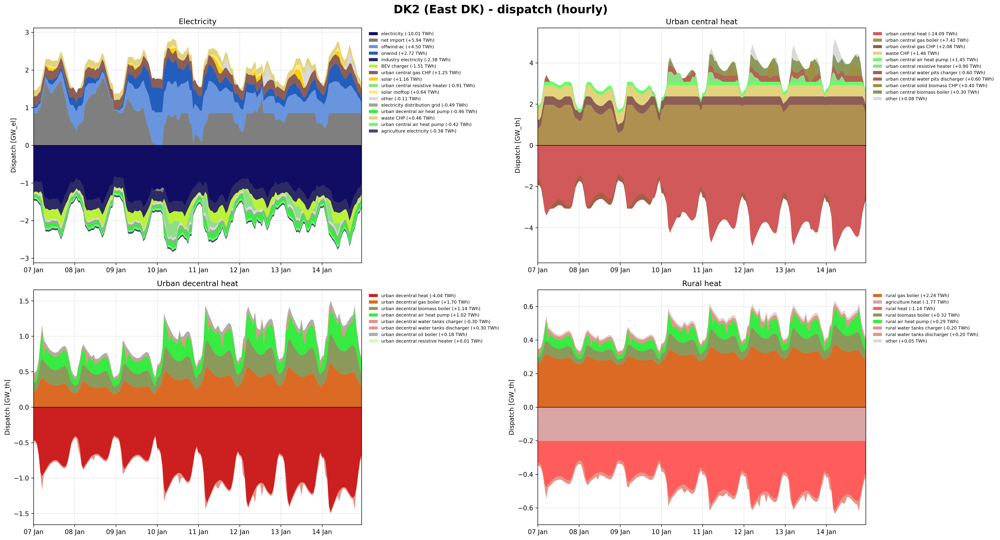

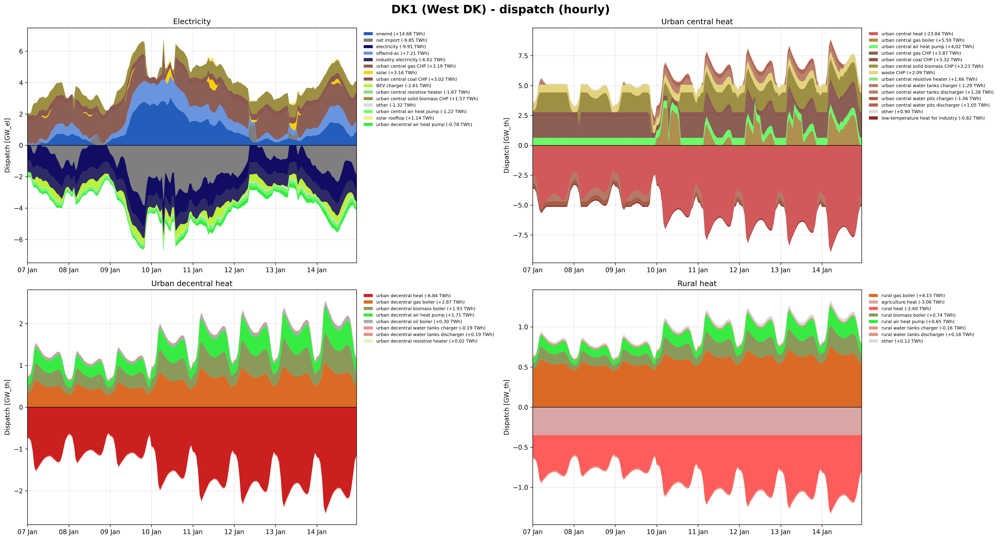

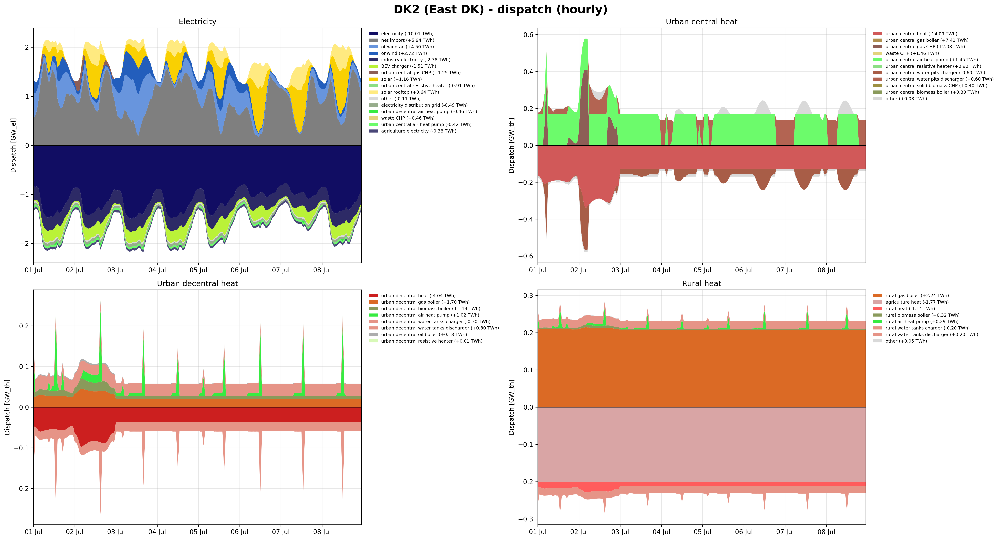

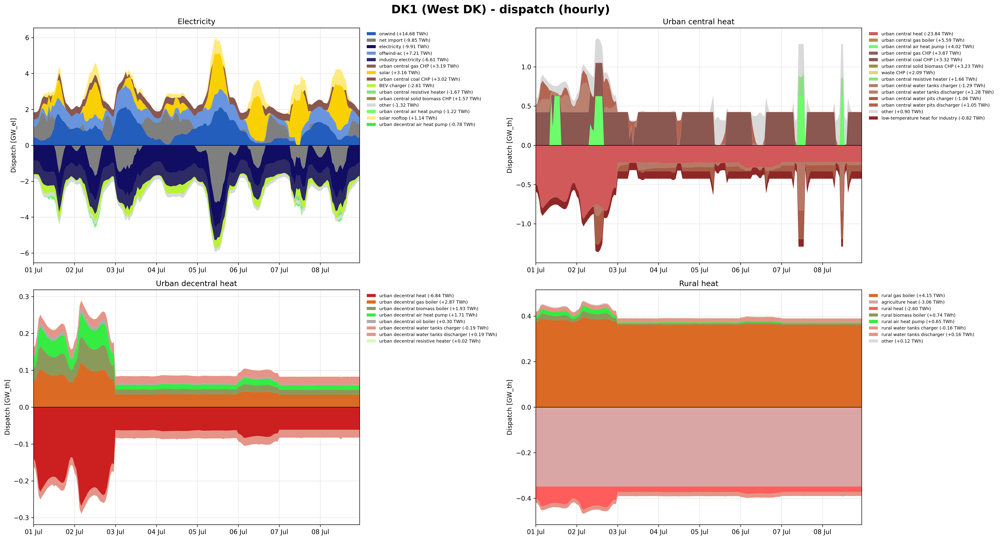

In [6]:
# Zoom: hourly dispatch for one winter and one summer week (Danish nodes)
dk_nodes = [x for x in NODE_NAMES.values() if x.startswith("DK")]
plot_node_dispatch(n, freq=None, period=("2013-01-07", "2013-01-14"), nodes=dk_nodes);
plot_node_dispatch(n, freq=None, period=("2013-07-01", "2013-07-08"), nodes=dk_nodes);

In [7]:
#Cell 1 - Electricity: annual energy per node [TWh]
annual_energy(n, dfs["Electricity"]).pivot(index="carrier", columns="node", values="TWh").round(3)

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
BEV charger,-7.137,-2.607,-1.506,-0.582,-0.162,-0.001,-6.186,-2.287,-3.254,-2.409
CCGT,38.733,0.000,0.000,0.000,3.357,0.002,32.461,7.550,0.000,0.000
H2 Electrolysis,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
OCGT,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PHS,-4.106,NaN,NaN,NaN,NaN,NaN,-0.500,NaN,-0.002,-0.002
agriculture electricity,-3.379,-0.657,-0.380,-0.940,-0.038,-0.000,-1.447,-4.802,-0.416,-0.904
agriculture machinery electric,-2.839,-0.345,-0.199,-0.561,-0.008,-0.000,-0.310,-1.428,-0.089,-0.471
biomass,45.178,0.000,0.000,8.760,1.107,0.063,24.430,6.501,0.000,4.717
coal,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [8]:
#Cell 2 - Urban decentral heat: annual energy per node [TWh]
annual_energy(n, dfs["Urban decentral heat"]).pivot(index="carrier", columns="node", values="TWh").round(3)

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
low-temperature heat for industry,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
urban decentral air heat pump,0.012,1.714,1.020,0.010,1.685,0.000,2.861,0.001,27.692,33.598
urban decentral biomass boiler,0.000,1.933,1.143,0.001,0.022,0.000,0.002,0.000,0.001,0.002
urban decentral gas boiler,112.943,2.869,1.696,9.432,0.901,0.000,78.000,41.197,20.972,10.998
urban decentral heat,-447.354,-6.837,-4.042,-33.532,-3.690,0.000,-319.418,-108.665,-48.646,-44.543
urban decentral heat vent,NaN,NaN,NaN,NaN,NaN,-0.000,NaN,NaN,NaN,NaN
urban decentral oil boiler,334.400,0.305,0.180,20.463,1.093,0.000,238.573,67.467,0.000,0.003
urban decentral resistive heater,0.000,0.016,0.010,3.627,0.000,0.000,0.000,0.000,0.000,0.002
urban decentral solar thermal,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN


In [9]:
#Cell 3 - Rural heat: annual energy per node [TWh]
annual_energy(n, dfs["Rural heat"]).pivot(index="carrier", columns="node", values="TWh").round(3)

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
agriculture heat,-26.829,-3.055,-1.765,-5.637,-0.038,-0.000,-1.447,-24.529,-0.416,-4.100
rural air heat pump,0.012,0.652,0.287,0.011,2.087,0.038,33.500,0.001,5.748,9.013
rural biomass boiler,0.000,0.735,0.321,0.002,0.022,0.015,0.002,0.000,0.001,0.002
rural gas boiler,61.602,4.147,2.242,8.448,1.559,0.018,14.439,27.150,4.770,7.052
rural heat,-137.729,-2.601,-1.136,-9.995,-6.227,-0.071,-53.204,-6.913,-10.099,-11.956
rural oil boiler,102.945,0.116,0.051,3.031,2.611,0.000,6.912,4.291,0.001,0.003
rural resistive heater,0.000,0.006,0.003,4.141,0.000,0.000,0.000,0.000,0.001,0.003
rural water tanks charger,-0.161,-0.159,-0.203,-0.253,-0.374,-0.142,-2.730,-0.129,-0.268,-0.435
rural water tanks discharger,0.160,0.159,0.201,0.252,0.360,0.141,2.527,0.129,0.264,0.418
